In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.io as pio
from plotly.subplots import make_subplots
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

pio.templates.default = "plotly_white"

 <div dir="rtl" style="text-align: right;">

### 1-خواندن و آماده سازی داده ها

</div> 

In [2]:

data = pd.read_excel("nba_project_1.xlsx", sheet_name=None)
pg = data["Player_Per_Game"]
adv = data["Player_Advanced"].copy()
info = data["Players"].drop_duplicates("player_id").copy()

In [3]:
def fix(s):
    try:
        return s.encode("latin-1").decode("utf-8")
    except Exception:
        return s


def to_cm(h):
    try:
        feet, inch = str(h).split("-")
        return int(feet) * 30.48 + int(inch) * 2.54
    except ValueError:
        return None

info["height_cm"] = info.height.apply(to_cm)

In [4]:
league = data["League_Stats"]
league = league[(league.season_type == "Regular-Season") & (league.stat_mode == "per_game")]
league = league.dropna(subset=["pts_per_g"]).copy()
league["year"] = league.season.str[:4].astype(int) + 1   
league = league.sort_values("year")

pd.set_option("display.max_columns", None)
league.describe()
#league.head(10)

,ranker,age,weight,g,mp_per_g,fg_per_g,fga_per_g,fg3_per_g,fg3a_per_g,ft_per_g,fta_per_g,orb_per_g,drb_per_g,trb_per_g,ast_per_g,stl_per_g,blk_per_g,tov_per_g,pf_per_g,pts_per_g,fg_pct,fg3_pct,ft_pct,pace,efg_pct,tov_pct,orb_pct,ft_rate,off_rtg,ts_pct,mp,fg,fga,fg3,fg3a,ft,fta,orb,drb,trb,ast,stl,blk,tov,pf,pts,fg_per_poss,fga_per_poss,fg3_per_poss,fg3a_per_poss,ft_per_poss,fta_per_poss,orb_per_poss,drb_per_poss,trb_per_poss,ast_per_poss,stl_per_poss,blk_per_poss,tov_per_poss,pf_per_poss,pts_per_poss,year
count,89.000000,84.000000,84.000000,89.000000,71.000000,89.000000,89.000000,56.000000,56.000000,89.000000,89.000000,61.000000,61.00000,85.000000,89.000000,60.000000,60.000000,67.000000,89.000000,89.000000,89.000000,56.000000,89.000000,61.000000,89.000000,67.000000,61.000000,89.000000,61.000000,89.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,89.000000
mean,37.808989,26.538095,210.011905,812.741573,241.595775,39.674157,89.598876,5.167857,14.782143,21.506742,28.842697,13.216393,31.22459,49.143529,22.634831,7.758333,4.736667,16.065672,23.612360,104.114607,0.443135,0.329929,0.747506,98.326230,0.462303,13.834328,29.609836,0.239865,106.388525,0.510449,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1985.033708
std,24.656216,0.581006,7.802524,367.187391,0.366230,4.831938,7.803911,3.973279,10.749632,3.461010,4.993721,2.424952,2.05756,9.137123,3.232614,1.876012,1.191633,3.383048,2.412459,10.556434,0.042240,0.036236,0.022624,5.982221,0.054477,2.482213,3.888003,0.031006,3.789024,0.046977,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,22.467375
min,1.000000,24.800000,195.000000,192.000000,240.500000,25.900000,75.400000,0.500000,2.000000,15.900000,21.700000,9.700000,28.40000,41.000000,6.900000,0.700000,0.300000,1.300000,18.600000,67.800000,0.279000,0.238000,0.641000,88.900000,0.279000,1.100000,22.200000,0.171000,97.700000,0.326000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1947.000000
25%,15.000000,26.300000,204.000000,420.000000,241.400000,36.800000,83.000000,1.600000,5.225000,18.600000,24.900000,11.100000,29.30000,43.000000,21.400000,7.600000,4.800000,14.450000,21.800000,99.000000,0.439000,0.298500,0.737000,92.400000,0.441000,13.300000,26.500000,0.221000,104.500000,0.493000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1968.000000
50%,37.000000,26.550000,208.000000,943.000000,241.600000,41.300000,88.800000,4.950000,14.200000,20.900000,27.800000,13.000000,30.50000,44.500000,22.900000,8.100000,5.000000,15.800000,23.900000,106.600000,0.456000,0.349000,0.751000,98.500000,0.477000,14.200000,30.500000,0.243000,106.400000,0.520000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1982.000000
75%,59.000000,26.800000,217.000000,1189.000000,241.850000,43.300000,95.300000,6.750000,18.800000,24.500000,33.100000,14.500000,33.00000,52.900000,24.600000,8.600000,5.225000,18.550000,25.600000,111.200000,0.466000,0.358000,0.763000,102.600000,0.495000,14.900000,32.900000,0.255000,108.000000,0.539000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2004.000000
max,81.000000,27.900000,224.000000,1230.000000,242.500000,45.900000,109.400000,13.500000,37.600000,28.600000,38.300000,19.800000,35.60000,73.500000,26.700000,9.900000,5.900000,20.800000,28.700000,118.800000,0.492000,0.367000,0.784000,111.100000,0.547000,16.500000,36.400000,0.333000,115.700000,0.581000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2026.000000


In [5]:
adv_cols = ["mp", "per", "ts_pct", "fg3a_per_fga_pct", "fta_per_fga_pct", "orb_pct", "drb_pct",
            "trb_pct", "ast_pct", "stl_pct", "blk_pct", "tov_pct", "usg_pct", "ows", "dws", "ws",
            "ws_per_48", "obpm", "dbpm", "bpm", "vorp"]
for c in adv_cols:
    adv[c] = pd.to_numeric(adv[c].astype(str).str.replace("'", "", regex=False), errors="coerce")



cols = ["player_id", "season_end", "team_name_abbr", "pts_per_g", "trb_per_g", "ast_per_g",
        "stl_per_g", "blk_per_g", "fg3a_per_g", "mp_per_g", "fg_pct"]
players = adv.merge(pg[cols], on=["player_id", "season_end", "team_name_abbr"])
players["name"] = players.name_display.map(fix)


players = players.sort_values("mp", ascending=False).drop_duplicates(["player_id", "season_end"])

In [6]:
#players.head(10)
players.describe()

,ranker,age,games,games_started,mp,per,ts_pct,fg3a_per_fga_pct,fta_per_fga_pct,orb_pct,drb_pct,trb_pct,ast_pct,stl_pct,blk_pct,tov_pct,usg_pct,ows,dws,ws,ws_per_48,obpm,dbpm,bpm,vorp,season_end,pts_per_g,trb_per_g,ast_per_g,stl_per_g,blk_per_g,fg3a_per_g,mp_per_g,fg_pct
count,2785.000000,2785.000000,2785.000000,2785.000000,2785.000000,2785.000000,2768.000000,2767.000000,2767.000000,2785.000000,2785.000000,2785.000000,2785.000000,2785.000000,2785.000000,2770.000000,2785.000000,2785.000000,2785.000000,2785.000000,2785.000000,2785.000000,2785.000000,2785.000000,2785.000000,2785.000000,2785.000000,2785.000000,2785.000000,2785.000000,2785.000000,2785.000000,2785.000000,2767.000000
mean,279.704847,25.671095,44.445242,20.929982,1011.086894,12.894399,0.545243,0.396860,0.248145,5.136409,15.006248,10.066176,13.362154,1.550377,1.878887,12.454982,18.404309,1.112244,1.025637,2.139282,0.075089,-1.541041,-0.185961,-1.727648,0.509013,2022.030521,8.676804,3.522118,1.968079,0.609156,0.393250,2.723950,19.320539,0.449918
std,162.065608,4.171035,24.102108,25.563501,786.472991,6.730456,0.108734,0.219597,0.191573,4.811591,6.813242,5.021372,8.984643,1.304281,2.039294,6.520348,5.971655,1.708447,0.968622,2.472748,0.105158,3.936102,1.979689,5.033769,1.163320,1.403045,6.568549,2.410831,1.854398,0.399009,0.398594,2.249124,9.562687,0.113139
min,1.000000,19.000000,1.000000,0.000000,1.000000,-45.200000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-3.000000,-0.100000,-1.900000,-1.231000,-40.700000,-22.100000,-46.600000,-1.700000,2020.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.500000,0.000000
25%,140.000000,23.000000,23.000000,0.000000,261.000000,9.800000,0.511000,0.259500,0.141500,2.000000,10.600000,6.600000,7.200000,1.000000,0.700000,9.300000,14.500000,0.000000,0.200000,0.200000,0.041000,-3.100000,-1.100000,-3.500000,-0.100000,2021.000000,3.800000,1.800000,0.700000,0.300000,0.100000,0.900000,11.600000,0.404000
50%,279.000000,25.000000,50.000000,7.000000,915.000000,12.800000,0.558000,0.406000,0.224000,3.600000,13.700000,8.900000,10.800000,1.400000,1.400000,11.800000,17.500000,0.500000,0.800000,1.300000,0.083000,-1.300000,-0.200000,-1.400000,0.100000,2022.000000,6.900000,3.100000,1.300000,0.600000,0.300000,2.300000,18.800000,0.447000
75%,418.000000,28.000000,65.000000,39.000000,1682.000000,16.300000,0.599000,0.540000,0.315000,7.000000,18.700000,12.600000,17.800000,1.900000,2.500000,14.700000,21.500000,1.700000,1.600000,3.400000,0.125000,0.400000,0.700000,0.600000,0.800000,2023.000000,11.800000,4.600000,2.600000,0.900000,0.500000,4.100000,27.600000,0.500000
max,605.000000,43.000000,84.000000,83.000000,2989.000000,76.200000,1.078000,1.000000,3.000000,80.900000,74.700000,53.900000,100.000000,25.000000,44.100000,100.000000,72.500000,12.200000,5.800000,17.000000,1.204000,31.000000,32.700000,48.600000,10.600000,2024.000000,34.700000,15.200000,11.700000,3.000000,3.600000,12.700000,43.500000,1.000000


 <div dir="rtl" style="text-align: right;">

### 2-رسم نمودار ها

</div> 

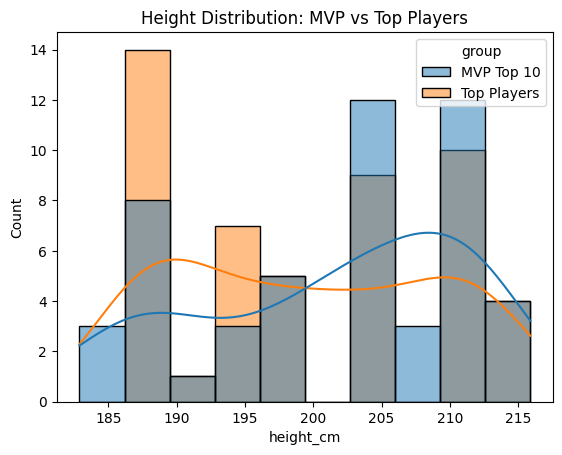

In [7]:
mvp = data["MVP"].copy()
mvp["rank_num"] = mvp["rank"].astype(str).str.replace("T", "").astype(int)   # "10T" -> 10

top_mvp = mvp[mvp.rank_num <= 10][["season_end", "player_id"]].assign(group="MVP Top 10")
top_pts = pg[pg.ranker <= 10][["season_end", "player_id"]].drop_duplicates().assign(group="Top Players")
heights = pd.concat([top_mvp, top_pts]).merge(info[["player_id", "height_cm"]], on="player_id", how="left")

sns.histplot(data=heights, x="height_cm", hue="group", bins=10, alpha=0.5, kde=True)
plt.title("Height Distribution: MVP vs Top Players")
plt.show()

In [8]:
pg.describe()

,ranker,age,games,games_started,mp_per_g,fg_per_g,fga_per_g,fg_pct,fg3_per_g,fg3a_per_g,fg3_pct,fg2_per_g,fg2a_per_g,fg2_pct,efg_pct,ft_per_g,fta_per_g,ft_pct,orb_per_g,drb_per_g,trb_per_g,ast_per_g,stl_per_g,blk_per_g,tov_per_g,pf_per_g,pts_per_g,season_end
count,3582.000000,3582.000000,3582.000000,3582.000000,3582.000000,3582.000000,3582.000000,3552.000000,3582.000000,3582.000000,3370.000000,3582.000000,3582.000000,3522.000000,3552.000000,3582.000000,3582.000000,3327.000000,3582.000000,3582.000000,3582.000000,3582.000000,3582.000000,3582.000000,3582.000000,3582.000000,3582.000000,3582.000000
mean,284.997767,25.980458,39.224456,17.889447,18.889028,3.062647,6.691541,0.446090,0.932524,2.661949,0.315356,2.131826,4.031519,0.514198,0.512354,1.276410,1.659269,0.749137,0.819682,2.610637,3.428141,1.903825,0.599442,0.383417,1.029313,1.604076,8.330039,2022.039643
std,157.254904,4.176791,24.338782,23.916102,9.433040,2.291633,4.726374,0.118539,0.856384,2.200590,0.133529,1.827435,3.303075,0.139030,0.119867,1.339528,1.641681,0.152855,0.733352,1.785481,2.355819,1.811692,0.403025,0.389464,0.801455,0.798868,6.350515,1.390354
min,1.000000,19.000000,1.000000,0.000000,0.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2020.000000
25%,153.000000,23.000000,17.000000,0.000000,11.500000,1.300000,3.200000,0.400000,0.200000,0.900000,0.278000,0.800000,1.600000,0.466250,0.478000,0.400000,0.600000,0.681000,0.300000,1.300000,1.700000,0.700000,0.300000,0.100000,0.500000,1.000000,3.700000,2021.000000
50%,289.000000,25.000000,40.000000,5.000000,18.200000,2.500000,5.500000,0.444000,0.700000,2.200000,0.338500,1.600000,3.000000,0.519000,0.524000,0.900000,1.200000,0.771000,0.600000,2.300000,3.000000,1.300000,0.500000,0.300000,0.800000,1.600000,6.700000,2022.000000
75%,418.750000,29.000000,61.000000,29.000000,26.700000,4.200000,9.100000,0.500000,1.400000,3.900000,0.384000,2.900000,5.500000,0.581000,0.569000,1.700000,2.200000,0.843000,1.100000,3.500000,4.500000,2.500000,0.800000,0.500000,1.400000,2.200000,11.300000,2023.000000
max,605.000000,43.000000,84.000000,83.000000,43.500000,11.500000,23.600000,1.000000,5.300000,12.700000,1.000000,11.000000,18.700000,1.000000,1.000000,10.200000,12.300000,1.000000,5.100000,11.400000,15.800000,11.700000,3.000000,3.600000,5.000000,5.000000,34.700000,2024.000000



<div dir="rtl" style="text-align: right;">

### معرفی ستون‌ها 

- **`season_end` — سال پایان فصل:** سالی که فصل مسابقات NBA در آن به پایان رسیده است.

- **`pts_per_g` — میانگین امتیاز در هر بازی:** میانگین تعداد امتیازهایی که بازیکن در هر مسابقه کسب کرده است.

- **`trb_per_g` — میانگین ریباند در هر بازی:** میانگین تعداد ریباندهای کل بازیکن در هر مسابقه؛ شامل ریباندهای دفاعی و هجومی.

- **`ast_per_g` — میانگین پاس گل در هر بازی:** میانگین تعداد پاس‌های منجر به امتیاز بازیکن در هر مسابقه.

</div>


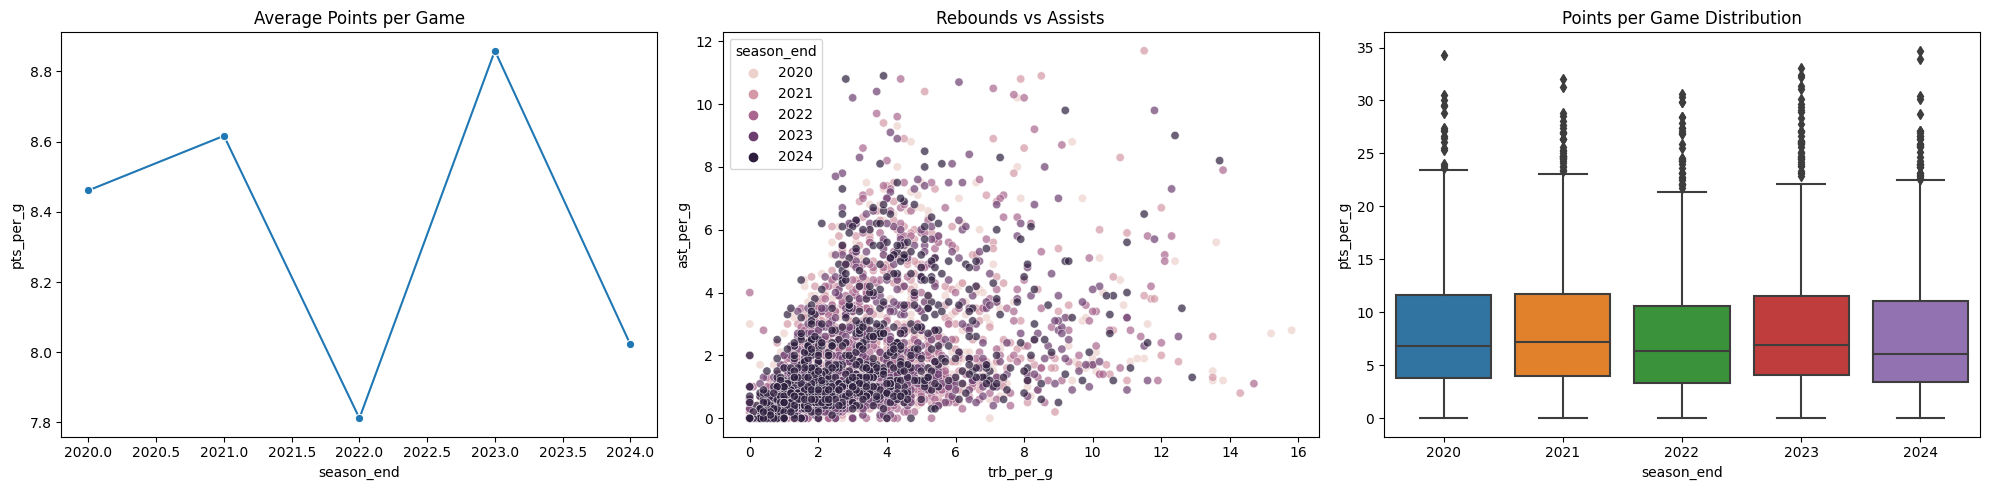

In [9]:
d = pg[["season_end", "pts_per_g", "trb_per_g", "ast_per_g"]].dropna()

fig, ax = plt.subplots(1, 3, figsize=(20, 5))
sns.lineplot(data=d, x="season_end", y="pts_per_g", errorbar=None, marker="o", ax=ax[0])
sns.scatterplot(data=d, x="trb_per_g", y="ast_per_g", hue="season_end", alpha=0.7, ax=ax[1])
sns.boxplot(data=d, x="season_end", y="pts_per_g", ax=ax[2])
ax[0].set_title("Average Points per Game")
ax[1].set_title("Rebounds vs Assists")
ax[2].set_title("Points per Game Distribution")
plt.tight_layout()
plt.show()

 <div dir="rtl" style="text-align: right;">

###  معرفی ستون‌ها 

- **`fg3a_per_g` — میانگین تلاش برای پرتاب سه‌امتیازی در هر بازی:** میانگین تعداد دفعاتی که بازیکن در هر مسابقه برای شوت سه‌امتیازی تلاش کرده است؛ چه شوت موفق باشد و چه ناموفق.

- **`fga_per_g` — میانگین تعداد کل تلاش‌های شوت‌زنی در هر بازی:** میانگین تعداد دفعاتی که بازیکن برای شوت‌های دو‌امتیازی و سه‌امتیازی تلاش کرده است؛ شامل شوت‌های موفق و ناموفق، بدون احتساب پرتاب‌های آزاد.

</div>

In [10]:
l3 = league[league.year >= 1980]
share = l3.fg3a_per_g / l3.fga_per_g * 100

fig = make_subplots(specs=[[{"secondary_y": True}]])
fig.add_bar(x=l3.year, y=l3.fg3a_per_g, name="3PA per game")
fig.add_scatter(x=l3.year, y=share, name="3PA share (%)", mode="lines+markers", secondary_y=True)
fig.update_layout(title="The 3-Point Revolution", height=500)
fig.show()

 <div dir="rtl" style="text-align: right;">

###  تحلیل روند استفاده از پرتاب‌های سه‌امتیازی در NBA

- **نسبت پرتاب‌های سه‌امتیازی به کل شوت‌ها:** نشان می‌دهد چه درصدی از تمام تلاش‌های شوت‌زنی بازیکنان از فاصلهٔ سه‌امتیازی انجام شده است؛ شامل شوت‌های موفق و ناموفق.
- **تغییرات تاریخی:** نمودار افزایش تدریجی سهم پرتاب‌های سه‌امتیازی را در طول فصل‌های NBA نشان می‌دهد. جهش قابل‌توجه در میانهٔ دههٔ ۱۹۹۰ با کوتاه‌شدن موقت فاصلهٔ خط سه‌امتیازی مرتبط است.
- **روند سال‌های اخیر:** افزایش این نسبت نشان می‌دهد که تیم‌ها به‌مرور سهم بیشتری از شوت‌های خود را به پرتاب‌های سه‌امتیازی اختصاص داده‌اند.

**منبع برای مطالعهٔ بیشتر:** [مقالهٔ NBA دربارهٔ تحول پرتاب‌های سه‌امتیازی](https://www.nba.com/news/3-point-era-nba-75)

</div>

In [11]:
from IPython.display import HTML, display

gif_url = "https://cdn.nba.com/manage/2021/10/01_League3Ptrend_small.gif"

display(HTML(f'<img src="{gif_url}" width="500">'))

<div dir="rtl" style="text-align: right;">

### معرفی ستون‌ها

- **`usg_pct` — درصد استفاده از مالکیت توپ:** نشان می‌دهد چه درصدی از مالکیت‌های تیم هنگام حضور بازیکن در زمین، با اقدام او برای شوت‌زدن، از دست دادن توپ یا گرفتن پرتاب آزاد به پایان می‌رسد. این شاخص میزان مشارکت بازیکن در حمله را نشان می‌دهد.

- **`ts_pct` — درصد شوت‌زنی واقعی:** معیاری برای سنجش کارایی امتیازگیری بازیکن است که شوت‌های دو‌امتیازی، سه‌امتیازی و پرتاب‌های آزاد را در نظر می‌گیرد.

- **`bpm` — امتیاز تأثیر بازیکن:** تخمینی از تأثیر کلی بازیکن بر عملکرد تیم، به ازای هر ۱۰۰ مالکیت توپ و در مقایسه با میانگین لیگ است. مقدار مثبت معمولاً نشان‌دهنده تأثیر بهتر از میانگین لیگ است.

- **`vorp` — ارزش بازیکن نسبت به بازیکن جایگزین:** تخمین می‌زند بازیکن در مقایسه با یک بازیکن جایگزین در سطح پایین‌تر، چه میزان ارزش اضافی برای تیم ایجاد می‌کند. مقدار بالاتر معمولاً نشان‌دهنده ارزش بیشتر است.

- **`ws` — بردهای کسب‌شده:** تخمینی از سهم بازیکن در پیروزی‌های تیم است که عملکرد تهاجمی و دفاعی او را در نظر می‌گیرد.

- **`mp` — مجموع دقایق بازی:** تعداد کل دقایقی که بازیکن در طول فصل در زمین حضور داشته است.

</div>

In [12]:
d = players[players.mp >= 1500].dropna(subset=["usg_pct", "ts_pct", "bpm", "vorp", "ws"]).copy()
d["size"] = d.ws.clip(lower=0.5)

fig = px.scatter_3d(d, x="usg_pct", y="ts_pct", z="bpm", color="vorp", size="size",
                    size_max=16, hover_name="name", opacity=0.8, color_continuous_scale="Turbo")
fig.update_layout(title="Player Impact (size = Win Shares, color = VORP)", height=550,width=650)
fig.show()


In [13]:
age = players[(players.mp >= 500) & players.age.between(19, 37)]

bpm_mean = age.groupby("age")["bpm"].mean()

player_count = age.groupby("age")["bpm"].count()

age = pd.DataFrame({
    "age": bpm_mean.index,
    "bpm": bpm_mean.values,
    "n": player_count.values
}).reset_index(drop=True)

fig = make_subplots(specs=[[{"secondary_y": True}]])
fig.add_bar(x=age.age, y=age.n, name="Number of players")
fig.add_scatter(x=age.age, y=age.bpm, name="Mean BPM", mode="lines+markers", secondary_y=True)
fig.update_layout(title="Aging Curve", height=400,width=1000)
fig.show()

In [14]:
seasons = data["Seasons"].copy()
seasons["mvp"] = seasons.mvp.map(fix)
top = seasons.mvp.value_counts().head(15).reset_index()
top.columns = ["player", "mvps"]

fig = px.bar(top, x="mvps", y="player", orientation="h", text="mvps", title="All-time MVP Awards")
fig.update_layout(yaxis=dict(categoryorder="total ascending"))
fig.show()

<div dir="rtl" style="text-align: right;">

### تحلیل جوایز MVP در تاریخ NBA

بر اساس نمودار، **کریم عبدالجبار (Kareem Abdul-Jabbar)** با کسب ۶ جایزه MVP، رکورددار بیشترین جوایز ارزشمندترین بازیکن فصل عادی NBA است. این موضوع نشان‌دهنده جایگاه برجسته او در تاریخ لیگ است.

**منبع:** [StatMuse – بازیکن NBA با بیشترین جوایز MVP](https://www.statmuse.com/nba/ask/nba-player-with-most-mvp-awards)

</div>

<div dir="rtl" style="text-align: right;">

### معرفی ستون‌ها

- **`franch_name` — نام فرنچایز:** نام تیم یا فرنچایز NBA را مشخص می‌کند که برای شناسایی و مقایسه تیم‌ها در نمودار استفاده می‌شود.

- **`g` — تعداد بازی‌ها:** تعداد بازی‌های ثبت‌شده برای فرنچایز را نشان می‌دهد. در این کد فقط فرنچایزهایی با حداقل ۱۵۰۰ بازی انتخاب شده‌اند.

- **`win_loss_pct` — درصد برد:** نسبت بردهای تیم به کل بازی‌های آن را نشان می‌دهد. مقدار بالاتر به معنای درصد موفقیت بیشتر در بازی‌هاست.

- **`wins` — تعداد بردها:** مجموع بردهای ثبت‌شده برای فرنچایز را نشان می‌دهد.

- **`years_playoffs` — سال‌های حضور در پلی‌آف:** تعداد سال‌هایی را نشان می‌دهد که فرنچایز در مرحله پلی‌آف حضور داشته است. در نمودار، این شاخص برای تعیین اندازه حباب‌ها استفاده می‌شود.

- **`years_league_champion` — سال‌های قهرمانی لیگ:** تعداد سال‌هایی را نشان می‌دهد که فرنچایز قهرمان لیگ شده است. این شاخص رنگ حباب‌ها را تعیین می‌کند.

- **`size` — اندازه حباب:** یک ستون محاسباتی است که از جمع `years_playoffs + 2` ساخته شده تا اندازه حباب‌ها بر اساس سابقه حضور در پلی‌آف تعیین شود و حباب‌ها اندازه صفر نداشته باشند.

</div>

In [15]:
teams = data["Teams"]
teams = teams[teams.franch_name.notna() & (teams.g >= 1500)].copy()
teams["size"] = teams.years_playoffs + 2

fig = px.scatter(teams, x="win_loss_pct", y="wins", size="size", color="years_league_champion",
                 text="franch_name", size_max=45, color_continuous_scale="YlOrRd")
fig.update_traces(textposition="top center", textfont_size=9)
fig.update_layout(title="Franchises: Wins vs Win % (size = playoff appearances)", height=650)
fig.show()

 <div dir="rtl" style="text-align: right;">

### 3-آزمون فرضیه ها

</div> 

 <div dir="rtl" style="text-align: right;">

### فرضیه اول: بررسی تغییر BMI بازیکنان برتر NBA در طول زمان

**هدف آزمون**

بررسی این ادعا که میانگین شاخص توده بدنی (BMI) در میان ۲۰ بازیکن برتر هر فصل NBA، در دو فصل اخیر نسبت به دو فصل قدیمی‌تر افزایش یافته است.

**تعریف متغیرها**

- **۲۰ بازیکن برتر هر فصل:** بر اساس ستون `ranker` در شیت `Player_Per_Game` انتخاب می‌شوند.
- **شاخص توده بدنی (`BMI`):** از تقسیم وزن بر مجذور قد بر حسب متر محاسبه می‌شود و برای مقایسه وضعیت بدنی بازیکنان به کار می‌رود.
- **گروه قدیم:** فصل‌های ۲۰۲۰–۲۱ و ۲۰۲۱–۲۲، با مقادیر `season_end` برابر ۲۰۲۱ و ۲۰۲۲.
- **گروه جدید:** فصل‌های ۲۰۲۲–۲۳ و ۲۰۲۳–۲۴، با مقادیر `season_end` برابر ۲۰۲۳ و ۲۰۲۴.

در هر گروه، در صورت انتخاب ۲۰ بازیکن در هر فصل، ۴۰ مشاهده بازیکن-فصل خواهیم داشت.

**فرضیه‌های آماری**

- \(H_0\): میانگین BMI گروه جدید کمتر یا مساوی گروه قدیم است.
- \(H_1\): میانگین BMI گروه جدید بیشتر از گروه قدیم است.

این آزمون یک‌طرفه است و هدف آن بررسی وجود شواهد آماری برای افزایش میانگین BMI در گروه جدید است.

</div> 

In [ ]:
top20 = pg[
    pg.season_end.isin([2021, 2022, 2023, 2024]) &
    (pg.ranker <= 20)
].drop_duplicates(["season_end", "player_id"])


info["bmi"] = info.weight * 0.453592 / (info.height_cm / 100) ** 2


bmi_df = top20.merge(
    info[["player_id", "bmi"]],
    on="player_id",
    how="left"
).dropna(subset=["bmi"])


bmi_df["period"] = np.where(
    bmi_df.season_end <= 2022, "2020-22", "2022-24"
)


old = bmi_df[bmi_df.period == "2020-22"]["bmi"]
new = bmi_df[bmi_df.period == "2022-24"]["bmi"]

print("Old period:", len(old))
print("New period:", len(new))

Old period: 40
New period: 40


In [28]:
comparison = bmi_df.groupby("period")["bmi"].agg(
    تعداد="count",
    میانگین="mean",
    میانه="median",
    انحراف_معیار="std",
    حداقل="min",
    حداکثر="max"
).round(2)

comparison = comparison.reindex(["2020-22", "2022-24"])
display(comparison)

,تعداد,میانگین,میانه,انحراف_معیار,حداقل,حداکثر
period,,,,,,
2020-22,40,25.30,25.27,2.16,21.06,32.82
2022-24,40,25.18,25.39,2.24,21.06,32.82


<div dir="rtl" style="text-align: right;">

### بررسی نرمال‌بودن داده‌ها

برای بررسی نرمال‌بودن توزیع BMI در دو دوره، از آزمون شاپیرو–ویلک استفاده می‌کنیم. فرض صفر این آزمون، نرمال‌بودن داده‌هاست. اگر مقدار \(p\) کمتر از ۰٫۰۵ باشد، فرض نرمال‌بودن رد می‌شود.

با توجه به غیرنرمال‌بودن داده‌ها در تحلیل حاضر، برای مقایسه دو گروه از آزمون ناپارامتری Mann–Whitney U استفاده می‌کنیم.

</div>

In [29]:
p_old = stats.shapiro(old).pvalue
p_new = stats.shapiro(new).pvalue

print(f"Shapiro old p-value: {p_old:.4f}")
print(f"Shapiro new p-value: {p_new:.4f}")

if p_old < 0.05 or p_new < 0.05:
    print(" توزیع نرمال ندارد.")
else:
    print("شواهد کافی برای رد نرمال‌بودن هیچ‌یک از گروه‌ها وجود ندارد.")

Shapiro old p-value: 0.0166
Shapiro new p-value: 0.0441
 توزیع نرمال ندارد.


<div dir="rtl" style="text-align: right;">

### **بینینگ BMI بر اساس طبقه‌بندی استاندارد شاخص توده بدنی**

برای دسته‌بندی مقادیر BMI بازیکنان، از طبقه‌بندی شاخص توده بدنی (BMI) ارائه‌شده در منبع [NCBI Bookshelf](https://www.ncbi.nlm.nih.gov/books/NBK278991/table/diet-treatment-obes.table4clas/) استفاده می‌کنیم. بر این اساس، مقادیر BMI به چهار گروه تقسیم می‌شوند:

- **کم‌وزن (Underweight):** کمتر از ۱۸٫۵
- **وزن طبیعی (Normal):** از ۱۸٫۵ تا کمتر از ۲۵
- **اضافه‌وزن (Overweight):** از ۲۵ تا کمتر از ۳۰
- **چاقی (Obese):** برابر یا بیشتر از ۳۰

این دسته‌بندی برای گروه‌بندی داده‌ها و مقایسه توزیع BMI در دوره‌های زمانی مختلف به کار می‌رود. از آنجا که BMI بین توده عضلانی و چربی بدن تمایز قائل نمی‌شود، تفسیر نتایج برای بازیکنان حرفه‌ای بسکتبال باید با احتیاط انجام شود.

**منبع:** [NCBI Bookshelf — Classification of BMI](https://www.ncbi.nlm.nih.gov/books/NBK278991/table/diet-treatment-obes.table4clas/)

</div>

In [30]:
bmi_df["bmi_group"] = pd.cut(
    bmi_df.bmi,
    bins=[0, 18.5, 25, 30, 100],
    labels=["Underweight", "Normal", "Overweight", "Obese"]
)


table = pd.crosstab(bmi_df.period, bmi_df.bmi_group)
display(table)


display((table.div(table.sum(axis=1), axis=0) * 100).round(1))

bmi_group,Normal,Overweight,Obese
period,,,
2020-22,15,24,1
2022-24,16,23,1


bmi_group,Normal,Overweight,Obese
period,,,
2020-22,37.5,60.0,2.5
2022-24,40.0,57.5,2.5


<div dir="rtl" style="text-align: right;">

### آزمون فرضیه با Mann–Whitney U

با توجه به غیرنرمال‌بودن داده‌ها، از آزمون Mann–Whitney U یک‌طرفه برای مقایسه دو دوره استفاده می‌کنیم.

- \(H_0\): میانگین BMI گروه جدید کمتر یا مساوی گروه قدیم است.
- \(H_1\): میانگین BMI گروه جدید بیشتر از گروه قدیم است.

سطح معناداری برابر ۰٫۰۵ در نظر گرفته می‌شود. اگر مقدار \(p\) کمتر از ۰٫۰۵ باشد، فرض صفر رد می‌شود؛ در غیر این صورت، شواهد کافی برای رد آن نداریم.

</div>

In [31]:
result = stats.mannwhitneyu(
    new,
    old,
    alternative="greater"
)

print(f"Mann-Whitney U: {result.statistic:.2f}")
print(f"p-value: {result.pvalue:.4f}")

if result.pvalue < 0.05:
    print("نتیجه: فرض صفر رد می‌شود؛ شواهد آماری به نفع بالاتر بودن BMI در دوره جدید وجود دارد.")
else:
    print("نتیجه: شواهد آماری کافی برای بالاتر بودن BMI در دوره جدید وجود ندارد.")

Mann-Whitney U: 783.50
p-value: 0.5651
نتیجه: شواهد آماری کافی برای بالاتر بودن BMI در دوره جدید وجود ندارد.


In [34]:
ALPHA = 0.05

def median_difference(old, new):
    return np.median(new) - np.median(old)

ci = stats.bootstrap(
    (old.to_numpy(), new.to_numpy()),
    statistic=median_difference,
    confidence_level=1 - ALPHA,
    method="percentile",
    n_resamples=10000,
    random_state=np.random.default_rng(42)
)

median_diff = new.median() - old.median()

print(f"Old median BMI: {old.median():.2f}")
print(f"New median BMI: {new.median():.2f}")
print(f"Median difference (New - Old): {median_diff:.2f}")
print(
    f"95% Bootstrap CI: "
    f"({ci.confidence_interval.low:.2f}, "
    f"{ci.confidence_interval.high:.2f})"
)

Old median BMI: 25.27
New median BMI: 25.39
Median difference (New - Old): 0.12
95% Bootstrap CI: (-0.93, 0.80)


<div dir="rtl" style="text-align: right;">

### نتیجه‌گیری فرضیه اول: مقایسه BMI بازیکنان برتر در دو دوره

میانه BMI بازیکنان منتخب از ۲۵٫۲۷ در دوره قدیم به ۲۵٫۳۹ در دوره جدید رسیده است؛ یعنی اختلاف مشاهده‌شده برابر با ۰٫۱۲ است. بااین‌حال، آزمون یک‌طرفه Mann–Whitney U مقدار `p-value = 0.5651` را نشان می‌دهد که از سطح معناداری ۰٫۰۵ بیشتر است.

همچنین، بازه اطمینان ۹۵ درصد اختلاف میانه‌ها برابر با ۰٫۹۳- تا ۰٫۸۰ است و صفر را در بر می‌گیرد. بنابراین، شواهد آماری کافی برای تأیید افزایش BMI در دوره جدید نسبت به دوره قدیم وجود ندارد و فرض صفر رد نمی‌شود.

این نتیجه به معنای اثبات برابری دو گروه نیست؛ بلکه داده‌های موجود برای تأیید افزایش آماری معنادار کافی نیستند.

</div>

<div dir="rtl" style="text-align: right;">

### فرضیه دوم: بررسی شاخص تجربه نسبت به سن بازیکنان تیم‌های قهرمان NBA

**هدف آزمون**

بررسی این ادعا که شاخص تجربه نسبت به سن بازیکنان فعال تیم‌های قهرمان NBA در دو فصل اخیر، نسبت به دو فصل قدیمی‌تر افزایش یافته است.

**تعریف متغیرها**

- **شاخص تجربه نسبت به سن (`talent`):** از تقسیم سال‌های تجربه بازیکن بر سن او محاسبه می‌شود. سن از شیت `Champion_Totals` و سابقه از شیت `Champion_Rosters` استخراج شده است. برای بازیکنان تازه‌کار با مقدار `R`، سابقه صفر در نظر گرفته می‌شود. این شاخص یک معیار تقریبی است و توانایی ذاتی را مستقیماً اندازه‌گیری نمی‌کند.
- **بازیکنان فعال:** بازیکنانی که در فصل موردنظر حداقل یک بازی برای تیم قهرمان انجام داده‌اند (`games > 0`).
- **گروه قدیم:** فصل‌های ۲۰۲۰–۲۱ و ۲۰۲۱–۲۲، با `season_end` برابر ۲۰۲۱ و ۲۰۲۲؛ شامل ۳۹ مشاهده بازیکن-فصل.
- **گروه جدید:** فصل‌های ۲۰۲۲–۲۳ و ۲۰۲۳–۲۴، با `season_end` برابر ۲۰۲۳ و ۲۰۲۴؛ شامل ۳۷ مشاهده بازیکن-فصل.

**فرضیه‌های آماری**

- **فرض صفر (H₀):** توزیع شاخص تجربه نسبت به سن در گروه جدید به سمت مقادیر بالاتر جابه‌جا نشده است.
- **فرض مقابل (H₁):** توزیع شاخص تجربه نسبت به سن در گروه جدید به سمت مقادیر بالاتر جابه‌جا شده است.



In [37]:
totals = data["Champion_Totals"]
rosters = data["Champion_Rosters"].copy()


rosters["experience"] = pd.to_numeric(
    rosters.years_experience.replace("R", 0),
    errors="coerce"
)


talent_df = totals[
    (totals.games > 0) &
    (totals.season_end.isin([2021, 2022, 2023, 2024]))
].merge(
    rosters[["player_id", "season_end", "team_id", "experience"]],
    on=["player_id", "season_end", "team_id"],
    how="left"
).dropna(subset=["experience", "age"]).copy()


talent_df["talent"] = talent_df.experience / talent_df.age


talent_df["period"] = np.where(
    talent_df.season_end <= 2022, "2020-22", "2022-24"
)

old = talent_df[talent_df.period == "2020-22"]["talent"]
new = talent_df[talent_df.period == "2022-24"]["talent"]

print(talent_df.groupby("period").talent.agg(
    ["count", "mean", "median", "std"]
).round(3))

         count   mean  median    std
period                              
2020-22     39  0.167   0.138  0.128
2022-24     37  0.176   0.154  0.129


<div dir="rtl" style="text-align: right;">

### بررسی نرمال‌بودن شاخص تجربه نسبت به سن

برای بررسی نرمال‌بودن توزیع شاخص تجربه نسبت به سن در دو دوره، از آزمون شاپیرو–ویلک استفاده می‌کنیم. با توجه به غیرنرمال‌بودن داده‌ها، آزمون Mann–Whitney U را برای مقایسه دو گروه به کار می‌بریم.

</div>

In [111]:
print(f"Old period p-value: {stats.shapiro(old).pvalue:.4f}")
print(f"New period p-value: {stats.shapiro(new).pvalue:.4f}")

Old period p-value: 0.0216
New period p-value: 0.0481


In [38]:
result = stats.mannwhitneyu(
    new,
    old,
    alternative="greater"
)

print(f"U statistic: {result.statistic:.2f}")
print(f"p-value: {result.pvalue:.4f}")

if result.pvalue < 0.05:
    print("فرض صفر رد می‌شود؛ شواهد آماری به نفع بالاتر بودن شاخص در دوره جدید وجود دارد.")
else:
    print("شواهد آماری کافی برای بالاتر بودن شاخص در دوره جدید وجود ندارد.")

U statistic: 755.00
p-value: 0.3655
شواهد آماری کافی برای بالاتر بودن شاخص در دوره جدید وجود ندارد.


In [115]:
rng = np.random.default_rng(42)
diffs = []

old_values = old.to_numpy()
new_values = new.to_numpy()

for _ in range(10000):
    old_sample = rng.choice(old_values, len(old_values), replace=True)
    new_sample = rng.choice(new_values, len(new_values), replace=True)

    diffs.append(
        np.median(new_sample) - np.median(old_sample)
    )

low, high = np.percentile(diffs, [2.5, 97.5])

print(f"Old median: {np.median(old_values):.3f}")
print(f"New median: {np.median(new_values):.3f}")
print(f"Median difference (New - Old): {np.median(new_values) - np.median(old_values):.3f}")
print(f"95% Bootstrap CI: ({low:.3f}, {high:.3f})")

Old median: 0.138
New median: 0.154
Median difference (New - Old): 0.016
95% Bootstrap CI: (-0.086, 0.107)
